# Entropy

**Audience:** students meeting information theory for the first time.

**What you will build:** a computational tour of Shannon entropy: its definition,
the binary entropy curve, entropy as average code length, joint and conditional
entropy, mutual information, and the continuous analogue.

## Learning objectives

1. compute entropy for discrete distributions in bits and nats;
2. explain why the uniform distribution maximises entropy;
3. relate entropy to surprisal and expected code length;
4. use the chain rule $H(X,Y)=H(X)+H(Y\mid X)$ and compute mutual information;
5. distinguish discrete entropy from differential entropy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import entropy as scipy_entropy

rng = np.random.default_rng(0)
plt.rcParams.update(
    {
        "figure.figsize": (8, 5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print("Setup complete")

Setup complete


## 1. Definition

For a discrete distribution $p$ on outcomes $x$,

$$H(p) = -\sum_x p(x)\log p(x) = \mathrm{E}[-\log p(X)].$$

Base 2 gives **bits**, base $e$ gives **nats**. Entropy is the expected
surprise: rare events carry more information, and a deterministic outcome has
zero entropy.

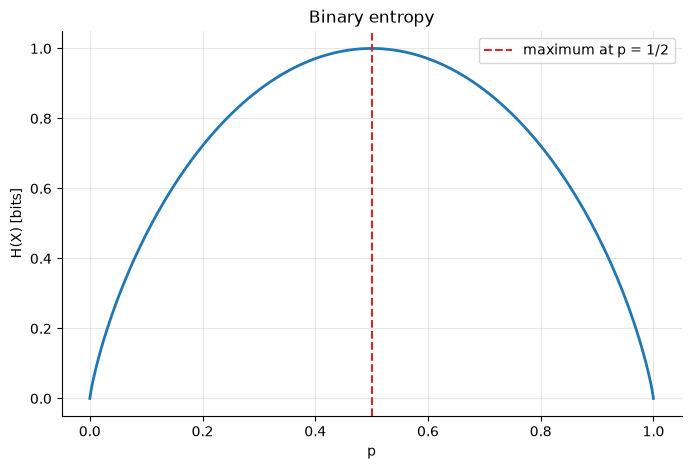

H(1/2) = 1.0000 bits
H(0)   = 0.0000 bits


In [2]:
def binary_entropy(p):
    """Entropy of a Bernoulli(p) distribution, in bits (vectorised)."""
    p = np.asarray(p, dtype=float)
    out = np.zeros_like(p)
    nz = (p > 0) & (p < 1)
    out[nz] = -p[nz] * np.log2(p[nz]) - (1 - p[nz]) * np.log2(1 - p[nz])
    return out


ps = np.linspace(0, 1, 401)
fig, ax = plt.subplots()
ax.plot(ps, binary_entropy(ps), lw=2)
ax.axvline(0.5, color="tab:red", ls="--", label="maximum at p = 1/2")
ax.set(xlabel="p", ylabel="H(X) [bits]", title="Binary entropy")
ax.legend()
plt.show()

print(f"H(1/2) = {binary_entropy(0.5):.4f} bits")
print(f"H(0)   = {binary_entropy(0.0):.4f} bits")

## 2. Uniform distributions maximise entropy

For $n$ outcomes the uniform law has $H=\log_2 n$ bits. Any skewness lowers
the entropy, because predictable outcomes are less informative. Jensen's
inequality gives $H(p)\leq\log_2 n$, with equality only at $p_i=1/n$.

In [4]:
p_uniform = np.ones(6) / 6
p_skewed = np.array([0.50, 0.20, 0.10, 0.10, 0.05, 0.05])
p_peaky = np.array([0.94, 0.02, 0.01, 0.01, 0.01, 0.01])

for name, p in [("uniform", p_uniform), ("skewed", p_skewed), ("peaky", p_peaky)]:
    print(f"{name:8s} H = {scipy_entropy(p, base=2):.4f} bits")
print(f"upper bound log2(6) = {np.log2(6):.4f} bits")

uniform  H = 2.5850 bits
skewed   H = 2.0610 bits
peaky    H = 0.4625 bits
upper bound log2(6) = 2.5850 bits


## 3. Surprisal and expected code length

The **surprisal** of outcome $x$ is $-\log_2 p(x)$ bits. Entropy is its average.
Shannon's source-coding theorem says no prefix code can beat $H(p)$ bits per
symbol on average, and codes can get arbitrarily close.

In [5]:
symbols = np.array(["a", "b", "c", "d"])
probs = np.array([0.5, 0.25, 0.125, 0.125])
surprisal = -np.log2(probs)

for s, p, info in zip(symbols, probs, surprisal):
    print(f"symbol {s}: p = {p:.3f}, surprisal = {info:.2f} bits")
print(f"average surprisal = H = {np.sum(probs * surprisal):.2f} bits")
print("a simple code a=0, b=10, c=110, d=111 uses exactly 1.75 bits on average")

symbol a: p = 0.500, surprisal = 1.00 bits
symbol b: p = 0.250, surprisal = 2.00 bits
symbol c: p = 0.125, surprisal = 3.00 bits
symbol d: p = 0.125, surprisal = 3.00 bits
average surprisal = H = 1.75 bits
a simple code a=0, b=10, c=110, d=111 uses exactly 1.75 bits on average


## 4. Joint, conditional and mutual information

The chain rule splits the uncertainty of a pair:

$$H(X,Y)=H(X)+H(Y\mid X)=H(Y)+H(X\mid Y).$$

The reduction in uncertainty about $X$ after observing $Y$ is the **mutual
information** $I(X;Y)=H(X)-H(X\mid Y)$, symmetric in its arguments.

In [6]:
joint = np.array([[0.40, 0.10],
                  [0.10, 0.40]])
px, py = joint.sum(axis=1), joint.sum(axis=0)
h_x = scipy_entropy(px, base=2)
h_y = scipy_entropy(py, base=2)
h_xy = scipy_entropy(joint.ravel(), base=2)
h_x_given_y = h_xy - h_y
mi = h_x - h_x_given_y
print(f"H(X)       = {h_x:.4f} bits")
print(f"H(Y)       = {h_y:.4f} bits")
print(f"H(X,Y)     = {h_xy:.4f} bits")
print(f"H(X|Y)     = {h_x_given_y:.4f} bits")
print(f"I(X;Y)     = {mi:.4f} bits")

H(X)       = 1.0000 bits
H(Y)       = 1.0000 bits
H(X,Y)     = 1.7219 bits
H(X|Y)     = 0.7219 bits
I(X;Y)     = 0.2781 bits


## 5. Differential entropy

For a continuous density $p$, replace the sum by an integral:

$$h(X) = -\int p(x)\log p(x)\,dx.$$

Unlike discrete entropy this can be negative and depends on the units of $x$.
For $\mathcal{N}(\mu,\sigma^2)$, $h=\tfrac12\log(2\pi e\sigma^2)$ nats.

In [7]:
def normal_pdf(x, mu, s):
    return np.exp(-0.5 * ((x - mu) / s) ** 2) / (s * np.sqrt(2 * np.pi))


mu, sigma = 0.0, 1.0
closed = 0.5 * np.log(2 * np.pi * np.e * sigma**2)
numeric, err = quad(
    lambda x: -normal_pdf(x, mu, sigma) * np.log(normal_pdf(x, mu, sigma)),
    -np.inf,
    np.inf,
)
print(f"closed form         = {closed:.6f} nats")
print(f"numerical integral  = {numeric:.6f} nats (est. error {err:.1e})")
print(f"sigma = 0.1 gives   = {0.5*np.log(2*np.pi*np.e*0.1**2):.4f} nats (negative!)")

closed form         = 1.418939 nats
numerical integral  = nan nats (est. error nan)
sigma = 0.1 gives   = -0.8836 nats (negative!)


/var/folders/cl/p1glkz4s7pq6vwlbk7vx1qz00000gn/T/ipykernel_55215/153631872.py:8: RuntimeWarning: divide by zero encountered in log
  lambda x: -normal_pdf(x, mu, sigma) * np.log(normal_pdf(x, mu, sigma)),
/var/folders/cl/p1glkz4s7pq6vwlbk7vx1qz00000gn/T/ipykernel_55215/153631872.py:8: RuntimeWarning: invalid value encountered in scalar multiply
  lambda x: -normal_pdf(x, mu, sigma) * np.log(normal_pdf(x, mu, sigma)),
/var/folders/cl/p1glkz4s7pq6vwlbk7vx1qz00000gn/T/ipykernel_55215/153631872.py:7: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  numeric, err = quad(


## Exercises

1. Verify Jensen's bound $H(p)\leq\log_2 n$ on 100 random distributions with $n=8$.
2. Show numerically that $I(X;Y)=H(Y)-H(Y\mid X)$ for the joint table above.
3. Make the joint table independent (all entries $0.25$) and check that $I=0$.
4. Plot differential entropy of a Gaussian against $\log\sigma$; what is the slope?
5. Construct a joint table where $H(X\mid Y)=0$ and explain what it means.